# Clindent data preprocessing

Synchronize `Force.csv` and `LVDT.csv`, repair short native LVDT spikes, and export each complete indentation cycle for GKV fitting. Run all cells with the **Dataprocess** environment. The default input is `data/Clindent_Data/400g/`, including `Trial0`, `Trial1`, and `Trial2`.

Each output CSV has exactly these columns: **`Time, s`**, **`Indentation Position, mm`**, **`Indentation Force, N`**. Both signals use **linear interpolation at 200 Hz** (0.005 s spacing) on a common grid. Every exported cycle starts at time zero. For example, three cycles from `Trial0` become `Trial0_1.csv`, `Trial0_2.csv`, and `Trial0_3.csv` in `data/Clindent_Data/400g/synchronized/`.

The controller's **moving to bottom** command marks indentation start; **moving to top** marks release. Keep the loading ramp and creep hold strictly before the release command; discard release and recovery. If no sequence log exists, force-based detection estimates these boundaries with a conservative release guard. Review the plots before running the final export cell. This notebook does not fit a model.

In [12]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'data_process' / 'utils' / 'creep_force_preprocessing.py').is_file():
            return candidate
    raise FileNotFoundError('Start the notebook from within the Tonometry_Control_Code project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from creep_force_preprocessing import (
    OUTPUT_COLUMNS, load_trial, detect_indentation_cycles, extract_indentation_cycles,
)

INPUT_DIR = PROJECT_ROOT / 'data' / 'Clindent_Data' / '400g'
OUTPUT_DIR = INPUT_DIR / 'synchronized'
TRIAL_NAMES = ['Trial0', 'Trial1', 'Trial2']  # Use None to discover all raw trial directories.
SAMPLING_HZ = 200.0
DT_S = 1.0 / SAMPLING_HZ
BASELINE_S = 0.8
MAX_INTERPOLATION_GAP_S = 0.2
FORCE_AXIS = 'Fz'
COMPRESSION_SIGN = -1.0
DISPLACEMENT_SIGN = 1.0
DISPLACEMENT_DESPIKE_SETTINGS = dict(
    window_s=0.2, threshold=0.12, n_sigma=6.0, max_duration_s=0.06, max_gap_s=0.2,
)
CYCLE_METHOD = 'auto'  # Prefer sequence logs; alternatives: 'sequence' or 'force'.
FORCE_SEGMENTATION_SETTINGS = dict(
    min_force_n=0.2, on_fraction=0.2, off_fraction=0.1, onset_fraction=0.05,
    debounce_s=0.1, min_loaded_s=5.0, smoothing_s=0.1,
)
FORCE_RELEASE_GUARD_S = 0.3  # Conservative trimming for force-only boundary estimates.
FORCE_PRE_INDENT_S = 0.2  # Preserve the initial ramp in the force-only fallback.
SAVE_FIGURES = False
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25})


def save_figure(fig, filename):
    if SAVE_FIGURES:
        figure_dir = OUTPUT_DIR / 'figures'
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_dir / filename, dpi=160, bbox_inches='tight')


print(f'Input: {INPUT_DIR}')
print(f'Output: {OUTPUT_DIR}')
print(f'Sampling: {SAMPLING_HZ:g} Hz; linear interpolation; dt = {DT_S:g} s')

Input: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g
Output: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g/synchronized
Sampling: 200 Hz; linear interpolation; dt = 0.005 s


## Clean native samples and synchronize

Use the recorded integer nanosecond timestamps with one shared origin, rather than aligning separate `elapsed_time` columns. Mask invalid LVDT voltages outside `(0.1, 9.99)` V. Repair only short returning excursions on the native LVDT timeline using linear interpolation; retain genuine steps. Do not smooth or despike force.

Subtract the median of the first 0.8 s from each native signal, then apply the configured signs so compression and indentation are positive. Preserve this **single trial-wide baseline** in every exported cycle, including residual indentation in later cycles. Do not zero displacement independently for each export.

Interpolate both cleaned signals directly from native samples onto the shared 200 Hz grid over their overlapping acquisition interval. There is no bin averaging or median resampling. Do not extrapolate or bridge sensor gaps longer than 0.2 s; reject any cycle containing an unresolved gap rather than deleting grid rows.

In [13]:
if TRIAL_NAMES is None:
    trial_dirs = sorted(
        path for path in INPUT_DIR.iterdir()
        if path.is_dir() and (path / 'Force.csv').is_file() and (path / 'LVDT.csv').is_file()
    )
else:
    if len(TRIAL_NAMES) != len(set(TRIAL_NAMES)):
        raise ValueError('TRIAL_NAMES must not contain duplicates.')
    trial_dirs = [INPUT_DIR / name for name in TRIAL_NAMES]
if not trial_dirs:
    raise FileNotFoundError(f'No raw Clindent trials were found in {INPUT_DIR}.')

processed = []
quality_rows = []
cycle_rows = []
for trial_dir in trial_dirs:
    trial = load_trial(
        trial_dir, dt=DT_S, baseline_s=BASELINE_S, max_gap_s=MAX_INTERPOLATION_GAP_S,
        force_axis=FORCE_AXIS, compression_sign=COMPRESSION_SIGN,
        displacement_sign=DISPLACEMENT_SIGN,
        displacement_despike=DISPLACEMENT_DESPIKE_SETTINGS, force_despike=None,
    )
    cycles = detect_indentation_cycles(
        trial_dir, trial, method=CYCLE_METHOD, force_settings=FORCE_SEGMENTATION_SETTINGS,
        force_release_guard_s=FORCE_RELEASE_GUARD_S, force_pre_indent_s=FORCE_PRE_INDENT_S,
    )
    if cycles.onset_s.min() < BASELINE_S:
        raise ValueError(f'{trial_dir.name}: Shorten BASELINE_S so it ends before indentation.')
    extracted = extract_indentation_cycles(trial['sync'], cycles, sampling_hz=SAMPLING_HZ)
    processed.append(dict(name=trial_dir.name, source=trial_dir, trial=trial,
                          cycles=cycles, extracted=extracted))
    quality_rows.append({
        'trial': trial_dir.name, 'force_samples': len(trial['force']),
        'lvdt_samples': len(trial['lvdt']),
        'invalid_lvdt_samples': int((~trial['lvdt'].sensor_valid).sum()),
        'repaired_lvdt_spikes': int(trial['lvdt'].displacement_spike.sum()),
        'unresolved_grid_samples': int((~trial['sync'].valid).sum()),
        'exported_cycles': len(extracted),
    })
    for event, (cycle_number, frame) in zip(cycles.itertuples(), extracted):
        retained = trial['sync'].loc[
            (trial['sync'].time_s >= event.onset_s) & (trial['sync'].time_s < event.release_s)
        ]
        cycle_rows.append({
            'file': f'{trial_dir.name}_{cycle_number}.csv',
            'source_trial': str(trial_dir.relative_to(PROJECT_ROOT)),
            'origin_ns': trial['origin_ns'], 'cycle': cycle_number,
            'boundary_source': event.boundary_source,
            'indent_command_s': event.onset_s, 'release_boundary_s': event.release_s,
            'first_retained_host_s': retained.time_s.iloc[0],
            'last_retained_host_s': retained.time_s.iloc[-1],
            'rows': len(frame), 'duration_s': frame[OUTPUT_COLUMNS[0]].iloc[-1],
            'sampling_hz': SAMPLING_HZ,
            'force_native_baseline_n': trial['baseline']['force_raw_n'],
            'position_native_baseline_mm': trial['baseline']['displacement_raw_mm'],
        })

quality_summary = pd.DataFrame(quality_rows)
cycle_summary = pd.DataFrame(cycle_rows)
display(quality_summary)
display(cycle_summary[['file', 'boundary_source', 'indent_command_s', 'release_boundary_s',
                       'rows', 'duration_s', 'sampling_hz']])

,trial,force_samples,lvdt_samples,invalid_lvdt_samples,repaired_lvdt_spikes,unresolved_grid_samples,exported_cycles
0,Trial0,221915,55882,4,215,0,3
1,Trial1,147072,45681,9,136,0,3
2,Trial2,363052,201619,28,965,0,3


,file,boundary_source,indent_command_s,release_boundary_s,rows,duration_s,sampling_hz
0,Trial0_1.csv,sequence,1.005704,62.763147,12351,61.750,200.0
1,Trial0_2.csv,sequence,93.162071,154.980562,12364,61.815,200.0
2,Trial0_3.csv,sequence,185.282192,247.087044,12361,61.800,200.0
3,Trial1_1.csv,sequence,1.004686,63.049349,12409,62.040,200.0
4,Trial1_2.csv,sequence,123.531710,185.278508,12349,61.740,200.0
5,Trial1_3.csv,sequence,245.645241,307.363794,12343,61.710,200.0
6,Trial2_1.csv,sequence,1.000144,152.885180,30377,151.880,200.0
7,Trial2_2.csv,sequence,303.187443,454.956828,30354,151.765,200.0
8,Trial2_3.csv,sequence,605.380839,757.152559,30354,151.765,200.0


## Check synchronization, spike removal, and cycle boundaries

Each shaded interval is retained. Dashed lines mark release boundaries. Gray LVDT traces show the valid native data before spike repair; the cleaned signal is interpolated at 200 Hz. Review the thresholds if real loading steps are marked as spikes. For force-only detection, boundaries are estimates and the release guard may remove the last part of the hold.

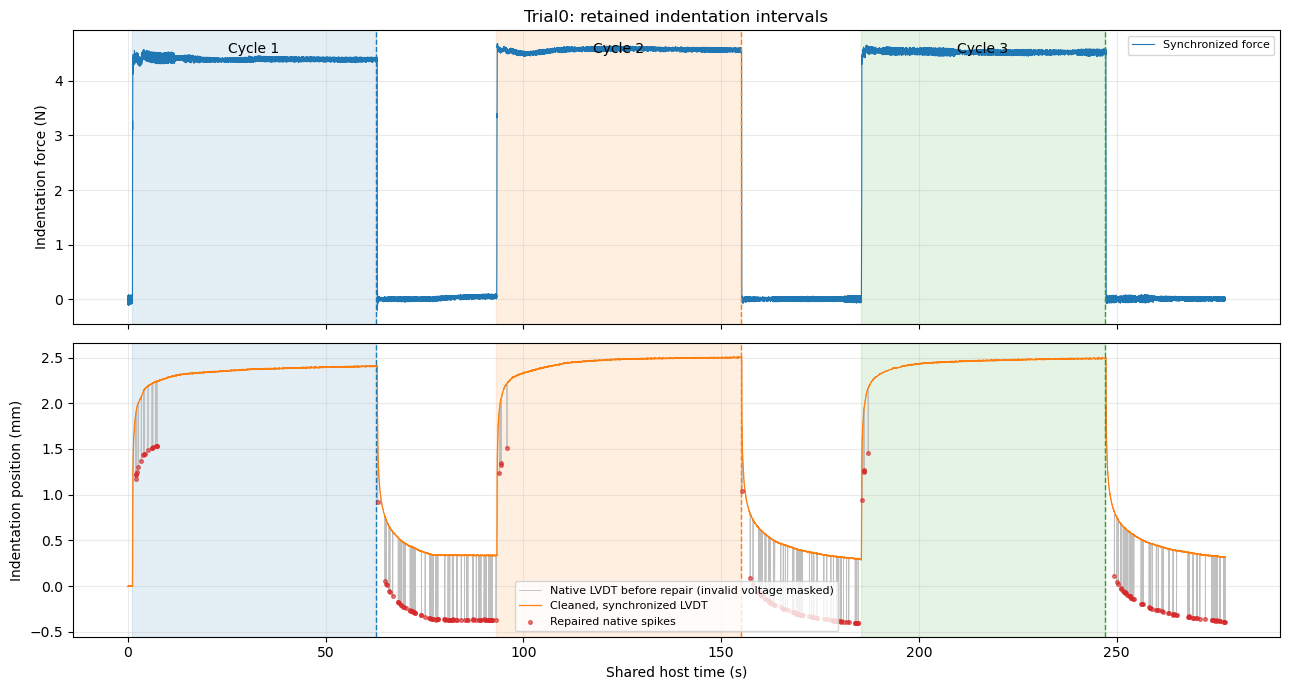

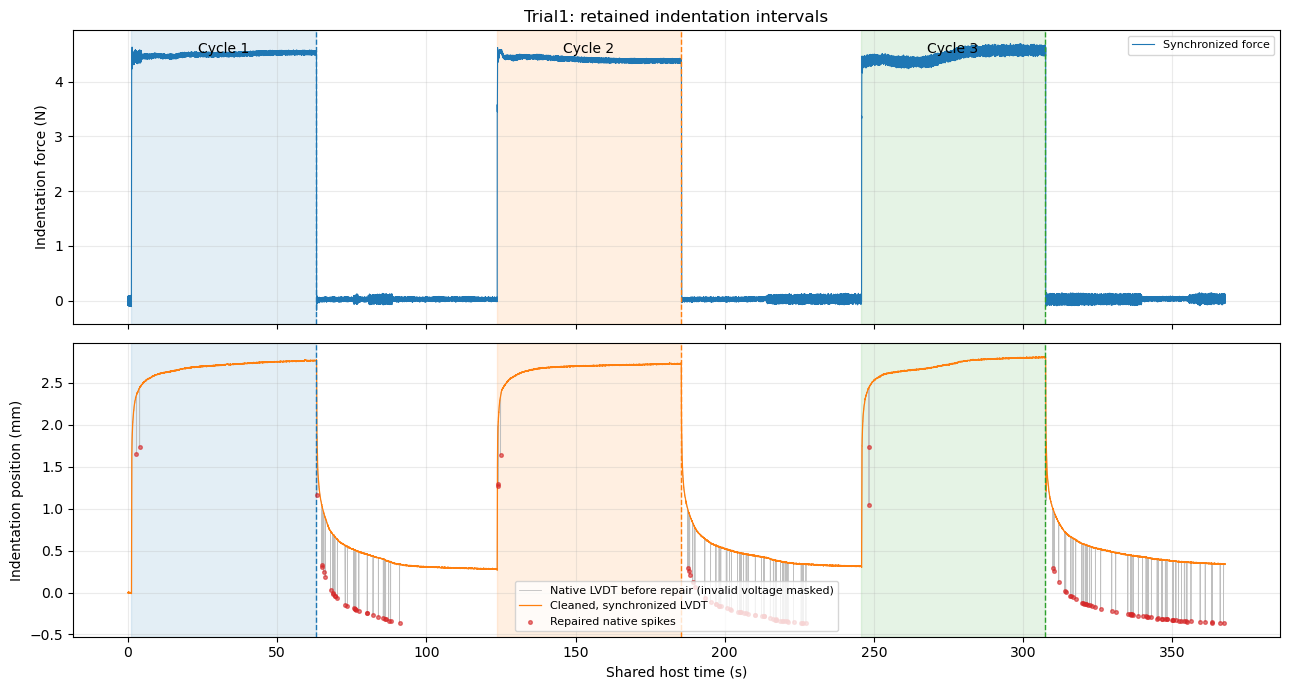

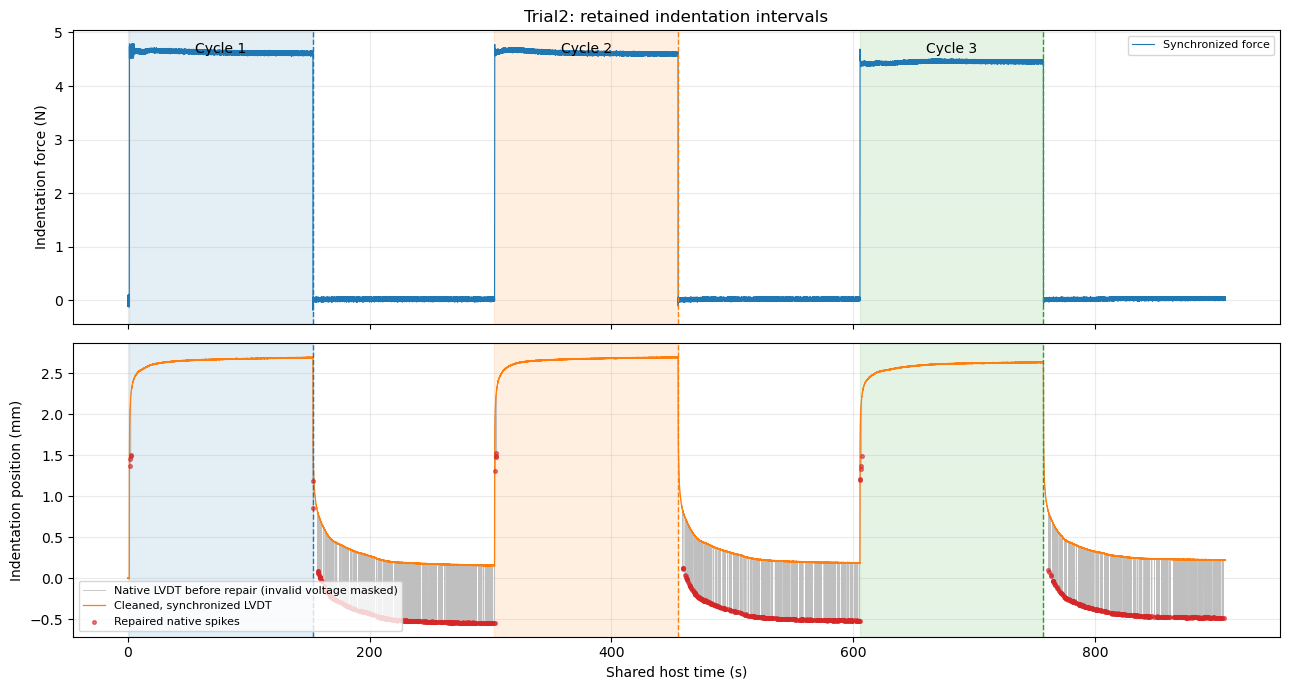

In [14]:
for result in processed:
    trial, cycles = result['trial'], result['cycles']
    sync, lvdt = trial['sync'], trial['lvdt']
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    axes[0].plot(sync.time_s, sync.force_n, color='tab:blue', lw=0.8, label='Synchronized force')
    axes[1].plot(lvdt.time_s, lvdt.displacement_before_despike_mm,
                 color='0.75', lw=0.6, label='Native LVDT before repair (invalid voltage masked)')
    axes[1].plot(sync.time_s, sync.displacement_mm, color='tab:orange', lw=0.9,
                 label='Cleaned, synchronized LVDT')
    spike = lvdt.displacement_spike
    axes[1].scatter(lvdt.loc[spike, 'time_s'], lvdt.loc[spike, 'displacement_before_despike_mm'],
                    color='tab:red', s=7, alpha=0.6, label='Repaired native spikes', zorder=3)
    for event in cycles.itertuples():
        color = plt.get_cmap('tab10')((event.cycle - 1) % 10)
        for axis in axes:
            axis.axvspan(event.onset_s, event.release_s, color=color, alpha=0.12)
            axis.axvline(event.release_s, color=color, ls='--', lw=1)
        axes[0].text((event.onset_s + event.release_s) / 2, 0.96, f'Cycle {event.cycle}',
                     transform=axes[0].get_xaxis_transform(), ha='center', va='top')
    axes[0].set(title=f"{result['name']}: retained indentation intervals", ylabel='Indentation force (N)')
    axes[1].set(xlabel='Shared host time (s)', ylabel='Indentation position (mm)')
    for axis in axes:
        axis.legend(loc='best', fontsize=8)
    fig.tight_layout()
    save_figure(fig, f"{result['name']}_synchronization.png")
    plt.show()

## Visualize every exported cycle

Columns show the individual cycle CSVs, with force and displacement sharing the same cycle-relative time axis. The three default trials each contain three cycles, producing nine CSVs in total. The final overlay compares all cycles within each raw trial.

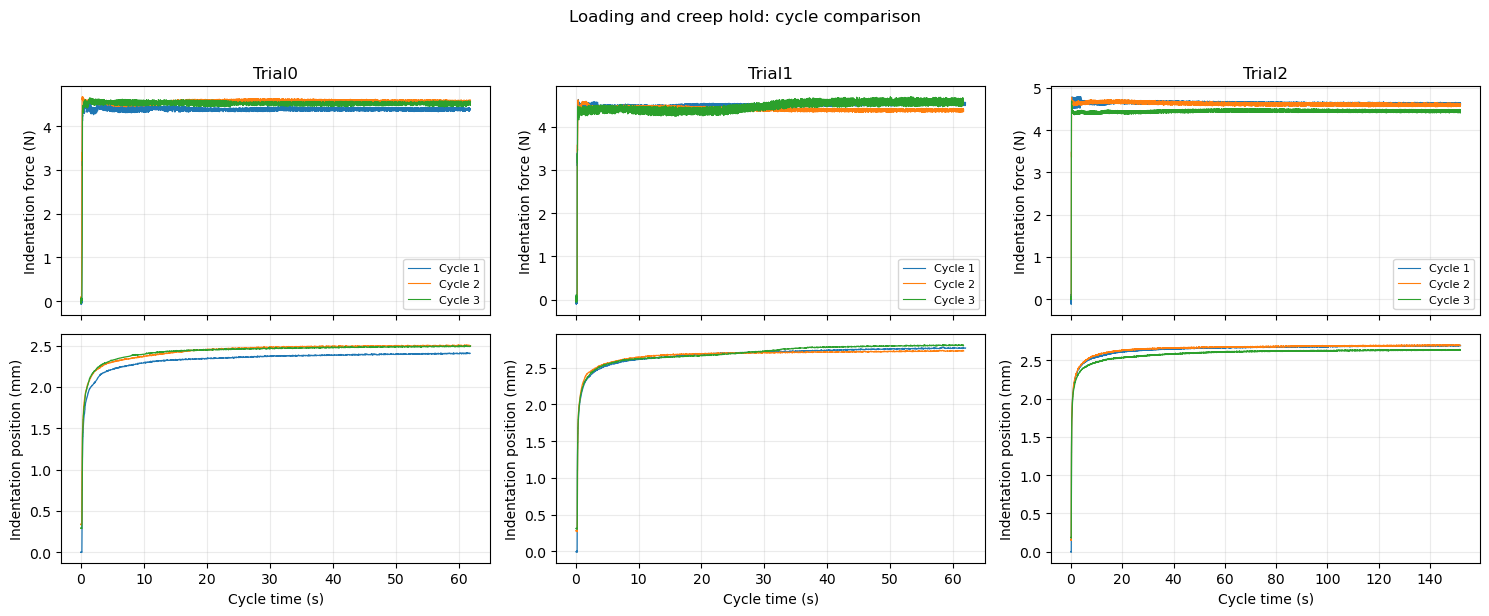

In [15]:
fig, axes = plt.subplots(2, len(processed), figsize=(5 * len(processed), 6),
                         sharex='col', squeeze=False)
for column, result in enumerate(processed):
    for cycle_number, frame in result['extracted']:
        time = frame[OUTPUT_COLUMNS[0]]
        line, = axes[0, column].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, label=f'Cycle {cycle_number}')
        axes[1, column].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, color=line.get_color())
    axes[0, column].set(title=result['name'], ylabel='Indentation force (N)')
    axes[1, column].set(xlabel='Cycle time (s)', ylabel='Indentation position (mm)')
    axes[0, column].legend(fontsize=8)
fig.suptitle('Loading and creep hold: cycle comparison', y=1.02)
fig.tight_layout()
# save_figure(fig, 'all_cycle_overlays.png')
plt.show()

## Export synchronized cycle CSVs

All selected trials and cycles have been validated before writing. Running this cell overwrites cycle CSVs for the selected raw trials and removes obsolete numbered cycle exports for those trials. Raw measurements remain untouched. `_cycle_manifest.csv` stores original timing, baseline, and boundary metadata separately so that every cycle CSV retains exactly the required three columns.

Next, open `data_process/Load_Profile-Creep_Curve_Fit_Kelvin.ipynb`. It reads these synchronized CSVs and performs GKV fitting without reading or preprocessing the raw recordings.

In [16]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exported_paths = []
for result in processed:
    expected_names = {f"{result['name']}_{cycle_number}.csv" for cycle_number, _ in result['extracted']}
    for cycle_number, frame in result['extracted']:
        output_path = OUTPUT_DIR / f"{result['name']}_{cycle_number}.csv"
        frame.to_csv(output_path, index=False, float_format='%.10f')
        exported_paths.append(output_path)
        print(f'{output_path.name}: {len(frame):,} rows at {SAMPLING_HZ:g} Hz')
    for old_path in OUTPUT_DIR.glob(f"{result['name']}_*.csv"):
        suffix = old_path.stem[len(result['name']) + 1:]
        if suffix.isdigit() and old_path.name not in expected_names:
            old_path.unlink()

manifest_path = OUTPUT_DIR / '_cycle_manifest.csv'
if manifest_path.exists():
    previous = pd.read_csv(manifest_path, dtype={'origin_ns': 'int64'})
    previous = previous.loc[~previous.source_trial.isin(cycle_summary.source_trial)]
    manifest = pd.concat([previous, cycle_summary], ignore_index=True)
else:
    manifest = cycle_summary
manifest.to_csv(manifest_path, index=False)
print(f'Saved {len(exported_paths)} cycle CSVs to {OUTPUT_DIR}')
display(pd.read_csv(exported_paths[0]).head())

Trial0_1.csv: 12,351 rows at 200 Hz
Trial0_2.csv: 12,364 rows at 200 Hz
Trial0_3.csv: 12,361 rows at 200 Hz
Trial1_1.csv: 12,409 rows at 200 Hz
Trial1_2.csv: 12,349 rows at 200 Hz
Trial1_3.csv: 12,343 rows at 200 Hz
Trial2_1.csv: 30,377 rows at 200 Hz
Trial2_2.csv: 30,354 rows at 200 Hz
Trial2_3.csv: 30,354 rows at 200 Hz
Saved 9 cycle CSVs to /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g/synchronized


,"Time, s","Indentation Position, mm","Indentation Force, N"
0,0.000,-0.002020,-0.056704
1,0.005,0.000925,0.034553
2,0.010,0.005371,0.001319
3,0.015,0.005371,-0.073270
4,0.020,0.005371,0.035373
